# 1. Постановка и календарные признаки

Линейная модель прогнозирует ряд как взвешенную сумму **признаков**. Сама по себе она ничего
не знает ни о дне недели, ни о сезоне, ни о вчерашних продажах: всё, что модель «видит», мы
должны явно закодировать.

В этом ноутбуке — признаки, которые зависят **только от даты** и поэтому известны на любой
горизонт: тренд, сезонность, праздники. План:

1. Постановка: горизонт, бэктест, baseline, утечка будущего.
2. Тренд и детрендинг.
3. Кодирование сезонности: dummy, Фурье, RBF, сплайны.
4. Праздники и события.

In [1]:
import common  # первым: глушит предупреждения ETNA при импорте

common.quiet()

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from etna.analysis import plot_backtest, plot_periodogram, plot_trend  # noqa: E402
from etna.models import LinearPerSegmentModel, SeasonalMovingAverageModel  # noqa: E402
from etna.pipeline import Pipeline  # noqa: E402
from etna.transforms import (  # noqa: E402
    ChangePointsTrendTransform,
    DateFlagsTransform,
    DifferencingTransform,
    EventTransform,
    FilterFeaturesTransform,
    FourierTransform,
    HolidayTransform,
    LagTransform,
    LinearTrendTransform,
    OneHotEncoderTransform,
    TheilSenTrendTransform,
)
from sklearn.preprocessing import SplineTransformer  # noqa: E402
from sktime.transformations.basisfunction import RBFTransformer  # noqa: E402


Fontconfig error: No writable cache directories
	/opt/homebrew/var/cache/fontconfig
	/Users/a.p.chikov/.cache/fontconfig
	/Users/a.p.chikov/.fontconfig


Matplotlib is building the font cache; this may take a moment.


## 1. Постановка задачи и утечка будущего

### Данные и горизонт

Дневная выручка от продаж лука за 3 года. Задача: каждый день прогнозировать на **14 дней вперёд**
(`HORIZON = 14`). В ETNA ряд хранится в `TSDataset`: колонки — пары (сегмент, признак).

segment,onion
feature,target
timestamp,
2018-01-01,5641.51
2018-01-02,17525.38
2018-01-03,22780.76
2018-01-04,23590.37
2018-01-05,29344.19


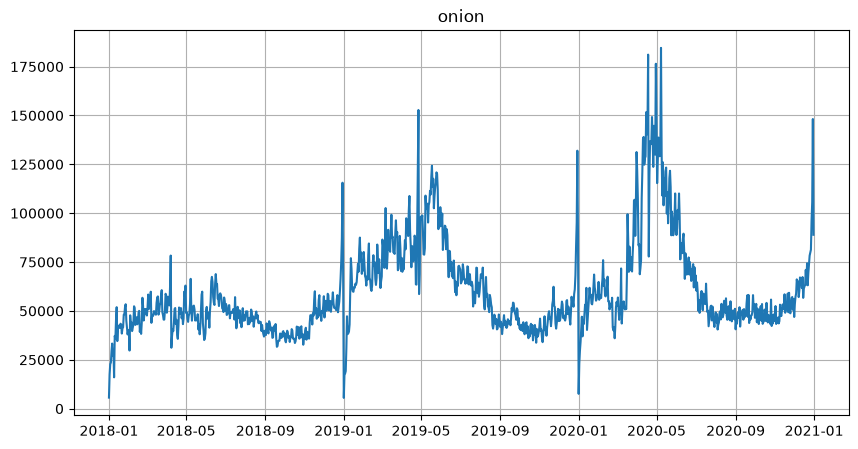

In [2]:
HORIZON = 14
onion = common.load_onion()
onion.plot()
onion.head()

### Честная оценка: бэктест

Случайное разбиение на train/test для рядов не годится: модель увидела бы будущее.
Бэктест режет ряд по времени: обучаемся на всём, что было до точки отсечки, и прогнозируем
следующие `HORIZON` дней. Так делаем несколько раз (`n_folds`) и усредняем метрику.

Первым всегда идёт **baseline** — самый простой разумный прогноз. Здесь это сезонный наивный
прогноз: «через неделю будет как неделю назад». Любой признак имеет смысл, только если с ним
модель обыгрывает baseline.

  train_end_time test_start_time test_end_time
0     2020-11-19      2020-11-20    2020-12-03
1     2020-12-03      2020-12-04    2020-12-17
2     2020-12-17      2020-12-18    2020-12-31


,WAPE,MAE
baseline,0.1427,10422.2221


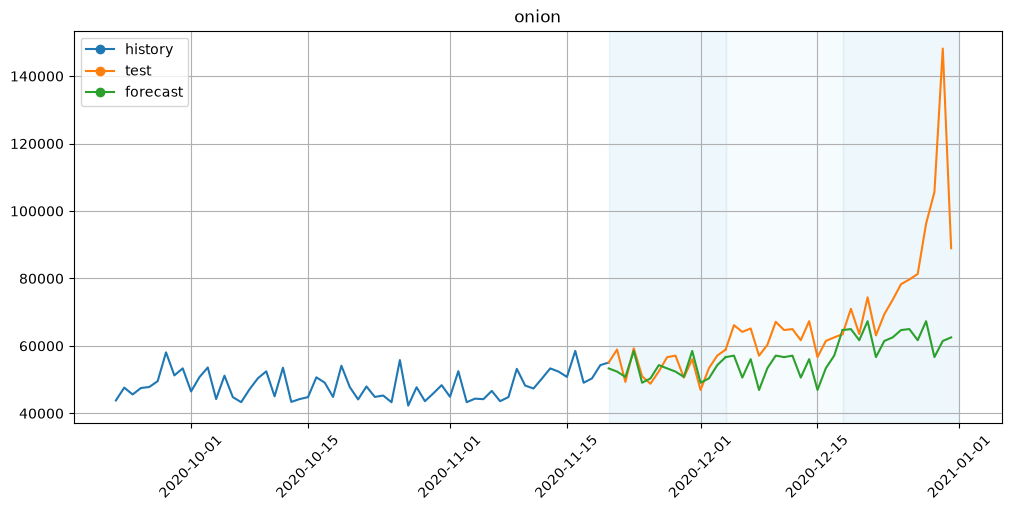

In [3]:
baseline = common.backtest(SeasonalMovingAverageModel(window=1, seasonality=7), [], onion, horizon=HORIZON)
print(baseline["fold_info"][["train_end_time", "test_start_time", "test_end_time"]])
plot_backtest(baseline["forecasts"], onion, history_len=60)
common.compare({"baseline": baseline})

### Какие признаки можно использовать

Главный вопрос к каждому признаку: **известен ли он на весь горизонт прогноза?**

| Признак | Известен на 14 дней вперёд? |
|---|---|
| день недели, месяц, праздники, гармоники Фурье, тренд по времени | да — зависит только от даты |
| промо-акции, цены, если они запланированы заранее | да |
| продажи вчера (лаг 1) | **нет** — для 14-го дня горизонта «вчера» ещё не наступило |
| продажи 14 дней назад (лаг 14) | да — даже для последнего дня горизонта это прошлое |
| погода, курс валют | нет — их самих надо прогнозировать |

Признак, который на обучении «подсматривает» будущее, называют **утечкой** (leakage):
на истории он красиво улучшает метрику, а в реальном прогнозе его просто нет.

### Пример утечки: лаг меньше горизонта

Добавим вчерашние продажи (`lags=[1]`). На обучающей истории признак заполнен, модель
обучится. Но в прогнозе на 14 дней лаг 1 есть только для первого дня — дальше `NaN`.
ETNA не даёт сделать вид, что всё хорошо, и падает на прогнозе.

In [4]:
train, _ = onion.train_test_split(test_size=HORIZON)
leaky = Pipeline(
    model=LinearPerSegmentModel(),
    transforms=[LagTransform(in_column="target", lags=[1], out_column="lag")],
    horizon=HORIZON,
)
try:
    leaky.fit(train).forecast()
except ValueError as error:
    print("Ошибка прогноза:", str(error).splitlines()[0])

Ошибка прогноза: Input X contains NaN.


Чинится сдвигом: берём лаги не меньше горизонта. Лаг 14 известен для каждого дня из 14.

In [5]:
honest = common.backtest(
    LinearPerSegmentModel(), [LagTransform(in_column="target", lags=[HORIZON], out_column="lag")], onion, HORIZON
)
common.compare({"baseline": baseline, "linear, lag 14": honest})

,WAPE,MAE
baseline,0.1427,10422.2221
"linear, lag 14",0.1387,10156.2548


Один честный лаг уже чуть лучше baseline: по сути модель выучила «через две недели будет
примерно как сейчас» с подобранным коэффициентом. Но она по-прежнему не знает ни дня недели,
ни сезона, ни праздников — дальше добавим то, чего ей не хватает. Лаги подробно разберём
в ноутбуке 2.

Заметьте: все три фолда приходятся на конец года — это осознанный выбор «последних данных»,
но в декабре особенно сильны праздничные эффекты, к ним вернёмся в разделе 4.

## 2. Тренд и детрендинг

Линейная модель умеет экстраполировать: если дать ей признак «номер дня», она продолжит
прямую в будущее. Это её сильная сторона (деревья так не умеют) и её же риск: неверно
заданный тренд уводит прогноз в сторону на всём горизонте.

В ETNA тренд — это трансформ: он оценивает тренд, **вычитает** его из ряда, модель учится
на остатке, а на прогнозе тренд **возвращается** автоматически (`inverse_transform`).
Вручную это та же схема «обучить тренд → вычесть → модель → прибавить тренд»
(7.1.2 §14), только без ручного кода.

### Учебный ряд с изломом тренда

Два года дневных данных: рост, затем после 450-го дня падение, плюс недельная сезонность,
шум и десяток выбросов. Мы знаем «правду», поэтому видно, какой способ её находит.

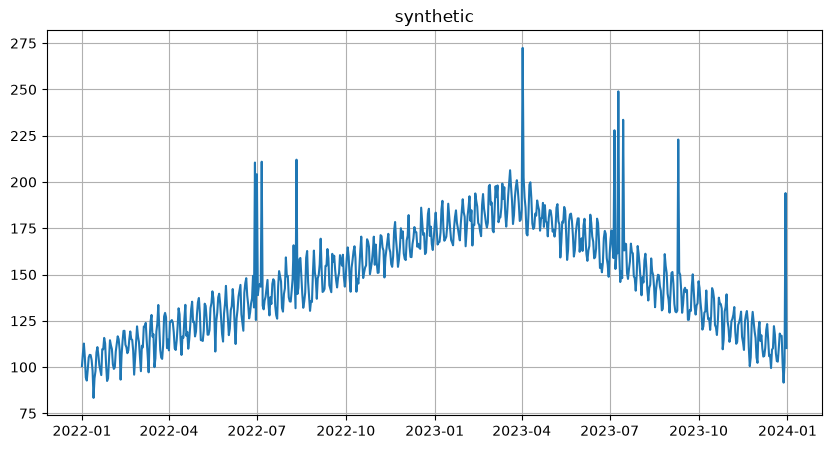

In [6]:
rng = np.random.default_rng(0)
t = np.arange(730)
true_trend = np.where(t < 450, 100 + 0.2 * t, 190 - 0.3 * (t - 450))
y = true_trend + 10 * np.sin(2 * np.pi * t / 7) + rng.normal(0, 4, t.size)
y[rng.choice(t.size, 10, replace=False)] += 80  # выбросы

broken = common.make_ts(
    pd.DataFrame({"timestamp": pd.date_range("2022-01-01", periods=t.size), "segment": "synthetic", "target": y})
)
broken.plot()

### Три способа оценить тренд

- `LinearTrendTransform` — одна прямая по МНК на всю историю (`poly_degree` — степень полинома);
- `TheilSenTrendTransform` — тоже прямая, но устойчивая к выбросам (медиана наклонов по парам точек);
- `ChangePointsTrendTransform` — ищет точки излома (по умолчанию алгоритм Binseg из `ruptures`,
  до 5 точек) и строит свою прямую на каждом отрезке.

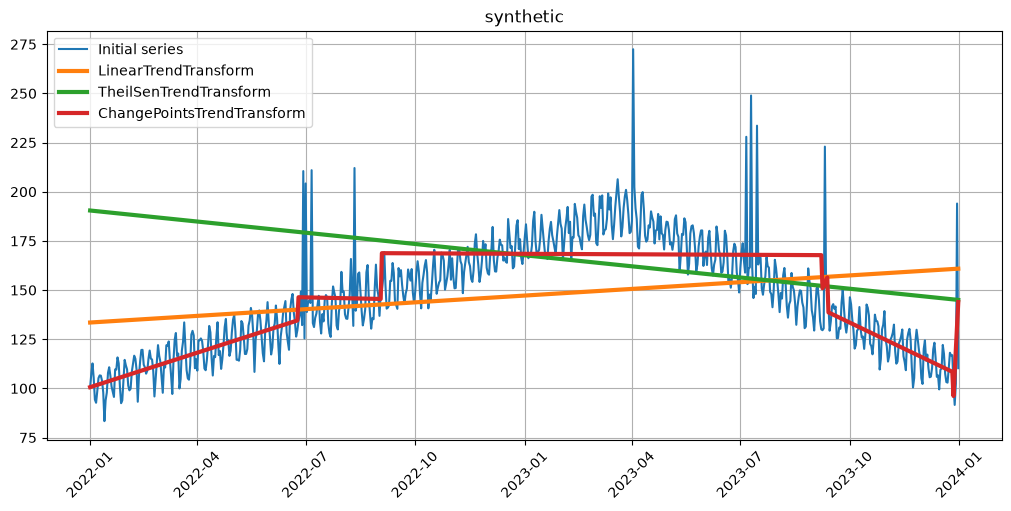

In [7]:
trends = {
    "linear": LinearTrendTransform(in_column="target"),
    "theil-sen": TheilSenTrendTransform(in_column="target"),
    "change points": ChangePointsTrendTransform(in_column="target"),
}
plot_trend(broken, list(trends.values()))

Одна прямая не может описать излом: она проводит компромисс через рост и падение.
Theil–Sen устойчив к выбросам, но от излома это не спасает.

Отрезочный тренд неидеален: Binseg ищет сдвиги **уровня**, а не наклона, поэтому отрезков
больше, чем изломов, и на границах видны ступеньки. Главный гиперпараметр — число точек
(`n_bkps` в `RupturesChangePointsModel`): мало точек — излом пропущен, много — тренд
начинает повторять шум. Для прогноза важнее всего **последний** отрезок: именно его наклон
продолжается в будущее, и здесь он найден верно.

Проверим прогнозом на 30 дней. Сезонность во всех вариантах одна и та же — недельные
гармоники (подробно в разделе 3), меняем только тренд. `DifferencingTransform` —
альтернатива: вместо оценки тренда модель учится на разностях `y[t] - y[t-1]`.

In [8]:
weekly = [FourierTransform(period=7, order=3, out_column="f7")]
variants = {"без тренда": []} | {name: [tr] for name, tr in trends.items()}
variants["разности"] = [DifferencingTransform(in_column="target", period=1)]
results = {name: common.backtest(LinearPerSegmentModel(), tr + weekly, broken, horizon=30) for name, tr in variants.items()}
common.compare(results)

,WAPE,MAE
без тренда,0.2546,30.2761
linear,0.4676,56.1435
theil-sen,0.6739,80.4843
change points,0.0389,4.6560
разности,0.0493,5.9043


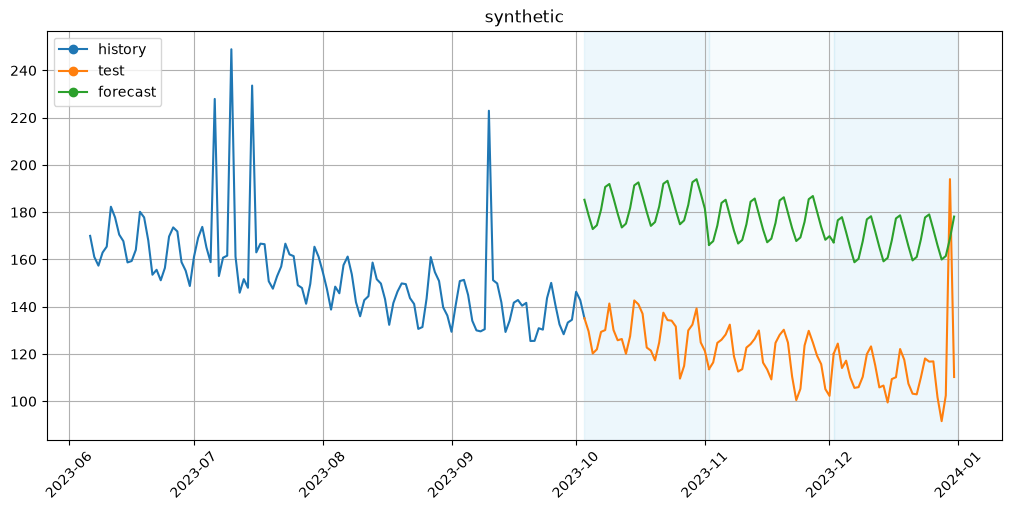

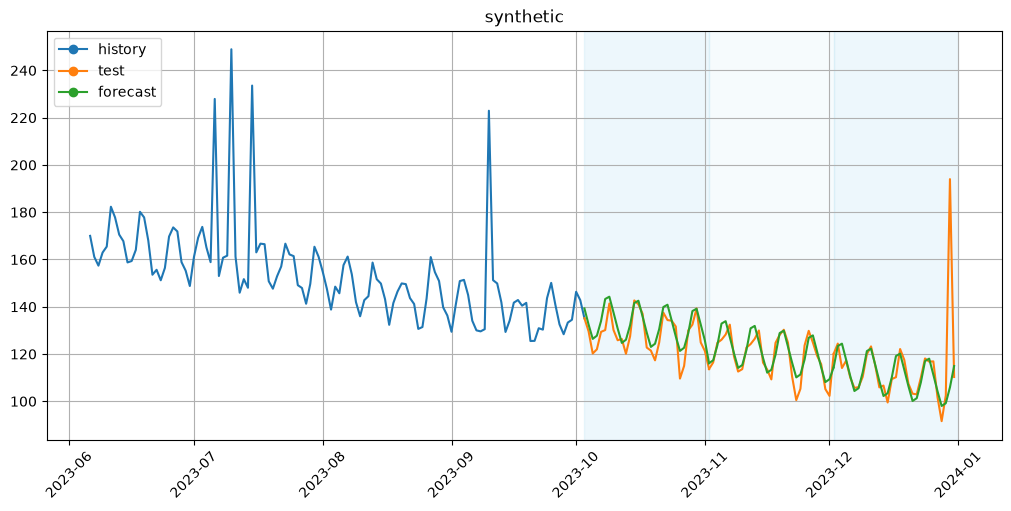

In [9]:
plot_backtest(results["linear"]["forecasts"], broken, history_len=120)
plot_backtest(results["change points"]["forecasts"], broken, history_len=120)

Прямая по всей истории тянет прогноз вверх, хотя ряд уже падает: её наклон наполовину
«помнит» старый рост. Отрезочный тренд продолжает последний отрезок.

### Осторожно на реальных данных

Тренд — сильное допущение. На продажах лука неправильный тренд хуже, чем никакого: годовая
волна (весенний пик) не объяснена признаками, и трансформ тренда начинает «ловить» её куски.

In [10]:
common.compare(
    {
        name: common.backtest(LinearPerSegmentModel(), tr + common.dow(), onion, HORIZON)
        for name, tr in {
            "день недели": [],
            "+ linear trend": [LinearTrendTransform(in_column="target")],
            "+ change points": [ChangePointsTrendTransform(in_column="target")],
        }.items()
    }
)

,WAPE,MAE
день недели,0.1493,10883.0745
+ linear trend,0.2087,13398.8565
+ change points,0.4837,32721.7019


Оба тренда ухудшают прогноз, change points — особенно: последний отрезок у него короткий
и попадает на сезонный подъём, который он продолжает как тренд.

**Вывод.** Тренд нужен, когда в ряде действительно есть долгое движение уровня, и
только вместе с признаками сезонности — иначе он подстраивается под сезонную волну.
Вернёмся к луку, когда добавим годовую сезонность.

## 3. Кодирование сезонности: dummy, Фурье, RBF, сплайны

Сезонность — это функция от «положения внутри цикла» (день недели, день года).
Линейная модель не умеет строить нелинейную функцию от одного числа, поэтому положение
в цикле нужно развернуть в **набор признаков**, линейная комбинация которых даст нужную
форму волны. Способов четыре:

| Кодировка | Признаки | Форма, которую можно собрать |
|---|---|---|
| dummy (one-hot) | индикатор месяца / дня недели | ступеньки |
| Фурье | пары `sin(2πkt/P)`, `cos(2πkt/P)`, `k = 1…order` | гладкая периодичная волна |
| RBF | «колокола» вокруг центров внутри цикла | гладкая, локально настраиваемая |
| сплайны | кусочные полиномы между узлами | гладкая, локально настраиваемая |

### Учебный ряд с известной годовой формой

Два года дневных данных. Годовой профиль несимметричный: острый весенний пик, плоское лето
и короткий ноябрьский всплеск — такие формы трудно описать одной синусоидой. Задача:
обучиться на двух годах и восстановить профиль третьего.

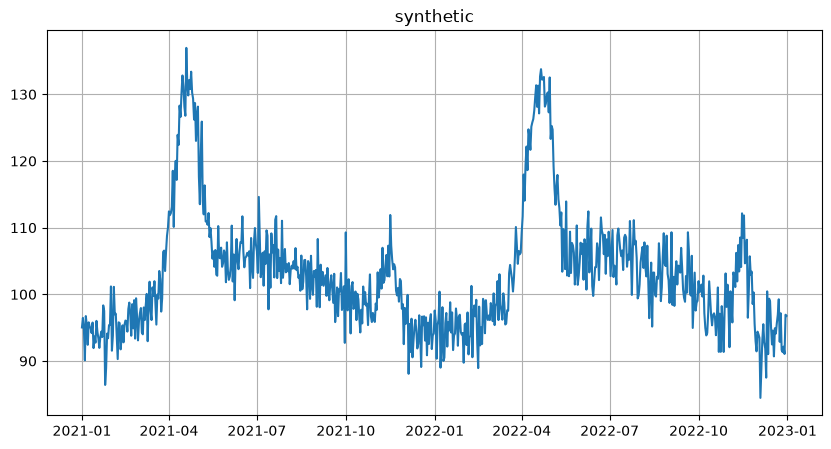

In [11]:
def true_profile(dates: pd.DatetimeIndex) -> np.ndarray:
    doy = dates.dayofyear.to_numpy()
    spring = 30 * np.exp(-(((doy - 110) / 18) ** 2))
    november = 12 * np.exp(-(((doy - 320) / 10) ** 2))
    return 100 + spring + november - 6 * np.cos(2 * np.pi * doy / 365.25)


history = pd.date_range("2021-01-01", "2022-12-31", freq="D")
future = pd.date_range("2023-01-01", "2023-12-31", freq="D")
rng = np.random.default_rng(1)
seasonal_df = pd.DataFrame(
    {"timestamp": history, "segment": "synthetic", "target": true_profile(history) + rng.normal(0, 3, history.size)}
)
common.make_ts(seasonal_df).plot()

### Четыре кодировки

Dummy и Фурье в ETNA есть готовые (`DateFlagsTransform` + `OneHotEncoderTransform`,
`FourierTransform`). RBF (sktime `RBFTransformer`) и сплайны (sklearn `SplineTransformer`)
— это преобразования **номера дня в году**. Номер дня известен для любой будущей даты,
поэтому такие признаки можно посчитать заранее и передать в `TSDataset` как known-future
экзогенные (`df_exog`).

In [12]:
def day_of_year_features(basis, prefix: str) -> pd.DataFrame:
    """Признаки basis(номер дня в году) для истории и прогнозного года, в длинном формате."""
    dates = history.append(future)
    values = basis(dates.dayofyear.to_numpy(dtype=float).reshape(-1, 1))
    features = pd.DataFrame(np.asarray(values), columns=[f"{prefix}_{i}" for i in range(np.shape(values)[1])])
    return features.assign(timestamp=dates, segment="synthetic")


def fitted(transformer):
    return transformer.fit(np.array([[1.0], [366.0]])).transform


month_dummies = [
    DateFlagsTransform(
        day_number_in_week=False, day_number_in_month=False, is_weekend=False, month_number_in_year=True, out_column="m"
    ),
    OneHotEncoderTransform(in_column="m_month_number_in_year", out_column="month"),
    FilterFeaturesTransform(exclude=["m_month_number_in_year"]),
]
encodings = {
    "dummy: 12 месяцев": (month_dummies, None),
    "Фурье: order=3": ([FourierTransform(period=365.25, order=3, out_column="f")], None),
    "Фурье: order=10": ([FourierTransform(period=365.25, order=10, out_column="f")], None),
    "RBF: 24 центра": (
        [],
        day_of_year_features(
            lambda doy: RBFTransformer(
                centers=np.linspace(1, 366, 24), gamma=1 / (2 * 8**2), apply_to="values"
            ).fit_transform(pd.DataFrame(doy)),
            "rbf",
        ),
    ),
    "сплайн: 24 узла, degree=3": (
        [],
        day_of_year_features(fitted(SplineTransformer(n_knots=24, degree=3, extrapolation="periodic")), "spl"),
    ),
}

Обучаемся на двух годах, прогнозируем год вперёд и сравниваем прогноз с истинным профилем.

In [13]:
truth = pd.Series(true_profile(future), index=future)
rows, forecasts = {}, {}
for name, (transforms, exog) in encodings.items():
    pipeline = Pipeline(LinearPerSegmentModel(), transforms, horizon=len(future))
    forecast = pipeline.fit(common.make_ts(seasonal_df, exog=exog)).forecast().to_pandas()[("synthetic", "target")]
    forecasts[name] = forecast
    n_features = len(pipeline.model._models["synthetic"].regressor_columns)
    rows[name] = {"признаков": n_features, "MAE к истинному профилю": (forecast - truth).abs().mean().round(2)}
pd.DataFrame(rows).T

,признаков,MAE к истинному профилю
dummy: 12 месяцев,12.0,1.69
Фурье: order=3,6.0,3.07
Фурье: order=10,20.0,0.61
RBF: 24 центра,24.0,0.55
"сплайн: 24 узла, degree=3",23.0,0.51


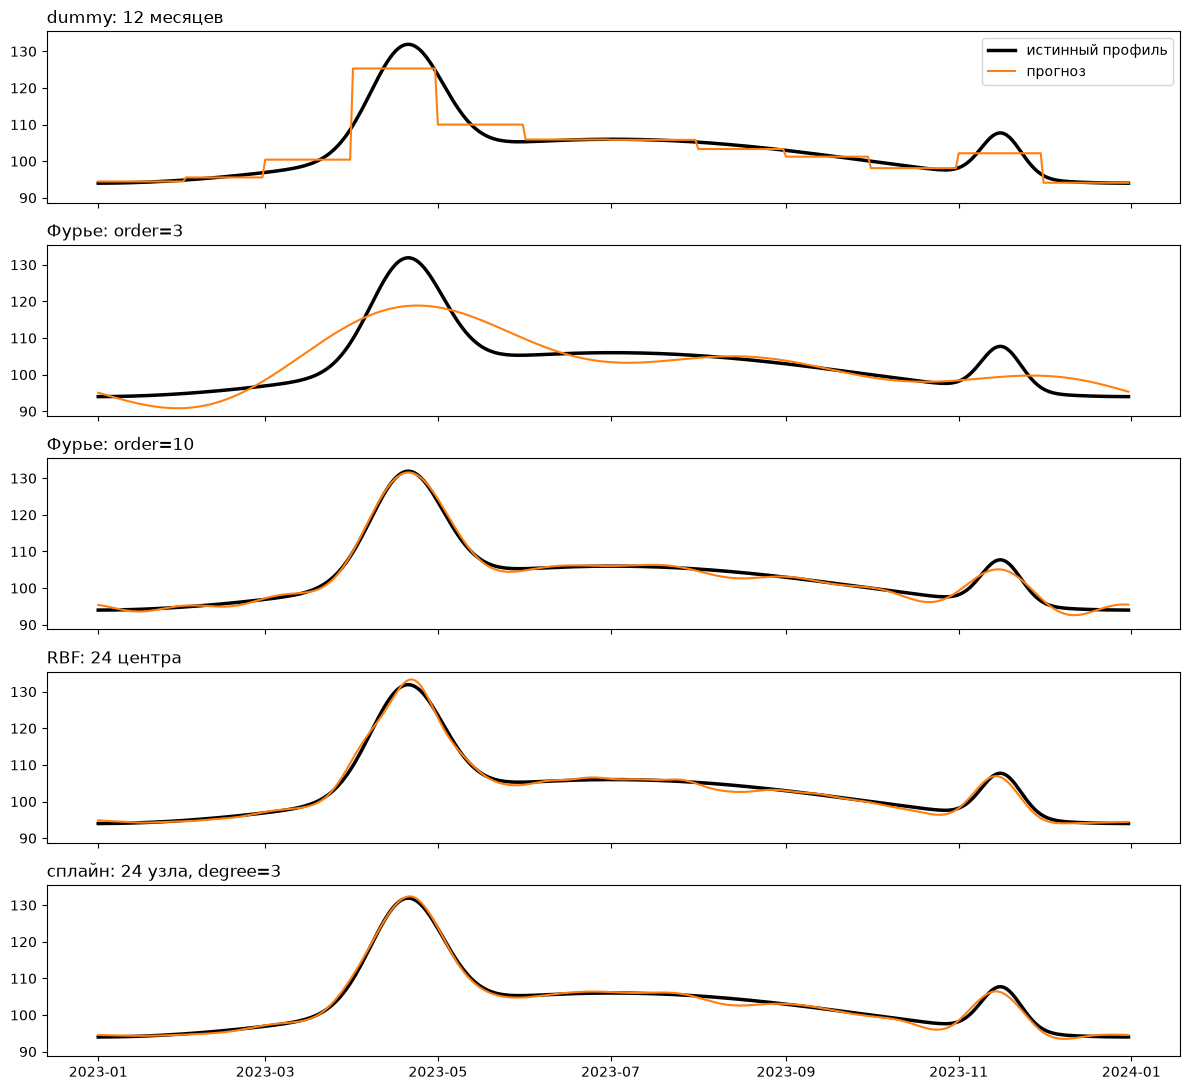

In [14]:
fig, axes = plt.subplots(len(forecasts), 1, figsize=(12, 2.2 * len(forecasts)), sharex=True, sharey=True)
for ax, (name, forecast) in zip(axes, forecasts.items()):
    ax.plot(truth, color="black", lw=2.5, label="истинный профиль")
    ax.plot(forecast, color="tab:orange", label="прогноз")
    ax.set_title(name, loc="left")
axes[0].legend(loc="upper right")
plt.tight_layout()

- **Dummy** дают ступеньки: внутри месяца сезонность постоянна, острый пик «размазан» по апрелю.
- **Фурье** с малым `order` — слишком гладкая волна, пик и ноябрьский всплеск срезаны.
  С `order=10` форма восстановлена.
- **RBF и сплайны** восстанавливают форму не хуже Фурье высокого порядка: каждый признак
  отвечает за свой участок года, поэтому острый пик описывается локально, не «раскачивая»
  остальной год. Тонкость RBF из sktime: расстояние до центра меряется по прямой, а не по
  кругу, поэтому центры нужно ставить и на начало, и на конец года (здесь: 1-й и 366-й день),
  иначе на стыке 31 декабря → 1 января появится скачок. `SplineTransformer` с
  `extrapolation="periodic"` замыкает год в кольцо сам.

### Гиперпараметры: сколько признаков нужно

У всех кодировок одна и та же дилемма: больше признаков — точнее форма, но выше риск
переобучения на шуме. Для Фурье это `order`. Посмотрим, как ошибка зависит от него.

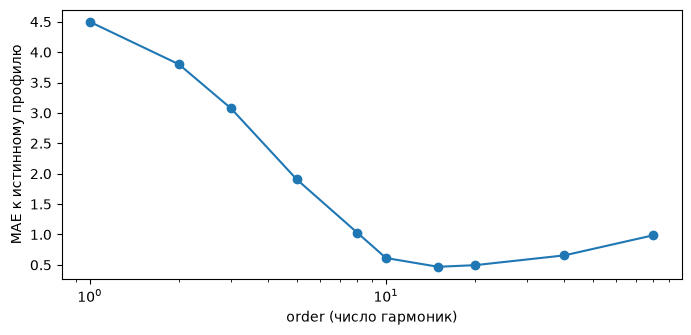

In [15]:
order_error = {}
for order in [1, 2, 3, 5, 8, 10, 15, 20, 40, 80]:
    pipeline = Pipeline(
        LinearPerSegmentModel(), [FourierTransform(period=365.25, order=order, out_column="f")], horizon=len(future)
    )
    forecast = pipeline.fit(common.make_ts(seasonal_df)).forecast().to_pandas()[("synthetic", "target")]
    order_error[order] = (forecast - truth).abs().mean()
ax = pd.Series(order_error).plot(marker="o", logx=True, figsize=(8, 3.5))
ax.set(xlabel="order (число гармоник)", ylabel="MAE к истинному профилю");

Ошибка быстро падает до `order ≈ 10`, затем выходит на плато и растёт: высокие гармоники
начинают описывать шум. Практические ориентиры из лонгрида (табл. 6):

| Сезонность | Период для дневного ряда | `order` |
|---|---|---|
| годовая | 365.24 | 2–4 … 10–20 |
| квартальная | 91.31 | 1–2 … 4–5 |
| месячная | 30.44 | 1–2 … 3–4 |
| недельная | 7 | 1–2 … 3 (максимум `ceil(7/2)`) |

Период — дробный (365.24, а не 365): иначе волна на длинной истории «уплывает» от календаря.
Нерегулярные всплески лучше описывать отдельным индикатором (раздел 4), а не поднимать `order`.

### Продажи лука

Какие периоды вообще есть в ряде, подсказывает периодограмма. С `period=365.25` по оси X —
число циклов в год: пики около 1–4 — годовая волна и её гармоники, пик около 52 — неделя
(52 цикла в год), около 104 и 156 — гармоники недельной волны.

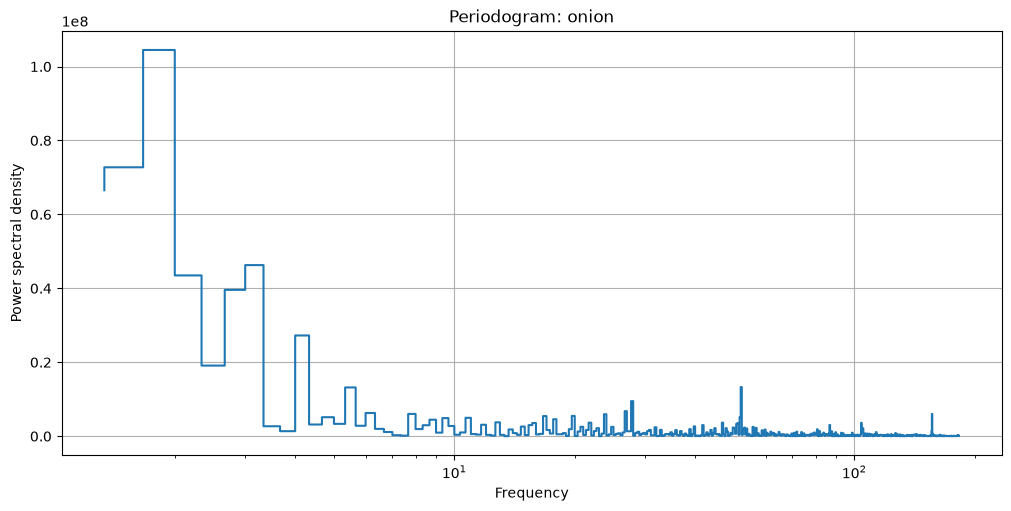

In [16]:
plot_periodogram(onion, period=365.25, amplitude_aggregation_mode="per-segment")

Вспомним раздел 2: тренд вместе с днём недели ухудшал прогноз, потому что годовая волна
не была объяснена. Добавим годовые гармоники.

In [17]:
trend = [LinearTrendTransform(in_column="target")]
yearly = [FourierTransform(period=365.25, order=3, out_column="f365")]
common.compare(
    {
        name: common.backtest(LinearPerSegmentModel(), transforms, onion, HORIZON)
        for name, transforms in {
            "день недели": common.dow(),
            "+ тренд": trend + common.dow(),
            "+ тренд + годовой Фурье": trend + common.dow() + yearly,
        }.items()
    }
)

,WAPE,MAE
день недели,0.1493,10883.0745
+ тренд,0.2087,13398.8565
+ тренд + годовой Фурье,0.1161,8519.2149


Годовые гармоники объясняют весенний пик, и тренду больше не нужно под него подстраиваться:
ошибка падает почти вдвое. Тренд и сезонность нужно добавлять **вместе**.

## 4. Праздники и события

Праздник — это known-future признак: календарь известен на годы вперёд. Для линейной
модели это бинарный индикатор, коэффициент при котором — средний эффект праздника.

Важно, что эффект часто приходится **не на сам праздник**: люди закупаются заранее,
а после праздника спрос проседает. Поэтому кроме флага праздника нужны признаки окна
вокруг события.

### Государственные праздники: `HolidayTransform`

Календарь берётся из библиотеки `holidays` по коду страны. `mode="binary"` — флаг 0/1,
`mode="category"` — название праздника (тогда его нужно развернуть в one-hot).

In [18]:
base = trend + common.dow() + yearly  # итог раздела 3
holidays = HolidayTransform(iso_code="RUS", out_column="holiday")
flag = holidays.fit_transform(common.load_onion()).to_pandas()[("onion", "holiday")].astype(int)
print("Праздничных дней за 3 года:", flag.sum())
print("Даты 2020 года:", ", ".join(day.strftime("%d.%m") for day in flag[(flag == 1) & (flag.index.year == 2020)].index))

Праздничных дней за 3 года: 56
Даты 2020 года: 01.01, 02.01, 03.01, 04.01, 05.01, 06.01, 07.01, 08.01, 23.02, 24.02, 08.03, 09.03, 01.05, 04.05, 05.05, 09.05, 11.05, 12.06, 04.11


Сравним прогнозы с флагом праздника и без. Добавим ещё `EventTransform`: он строит по
бинарному флагу признаки «через сколько дней событие» (`n_pre`) и «сколько дней прошло»
(`n_post`) — в режиме `binary` это флаги «скоро праздник» / «недавно был праздник».

In [19]:
results = {
    "база": common.backtest(LinearPerSegmentModel(), base, onion, HORIZON),
    "+ праздники": common.backtest(LinearPerSegmentModel(), base + [holidays], onion, HORIZON),
    "+ праздники + окно 7 дней до": common.backtest(
        LinearPerSegmentModel(),
        base + [holidays, EventTransform(in_column="holiday", out_column="event", n_pre=7, n_post=1)],
        onion,
        HORIZON,
    ),
}
common.compare(results)

,WAPE,MAE
база,0.1161,8519.2149
+ праздники,0.1138,8195.6714
+ праздники + окно 7 дней до,0.1131,8177.3845


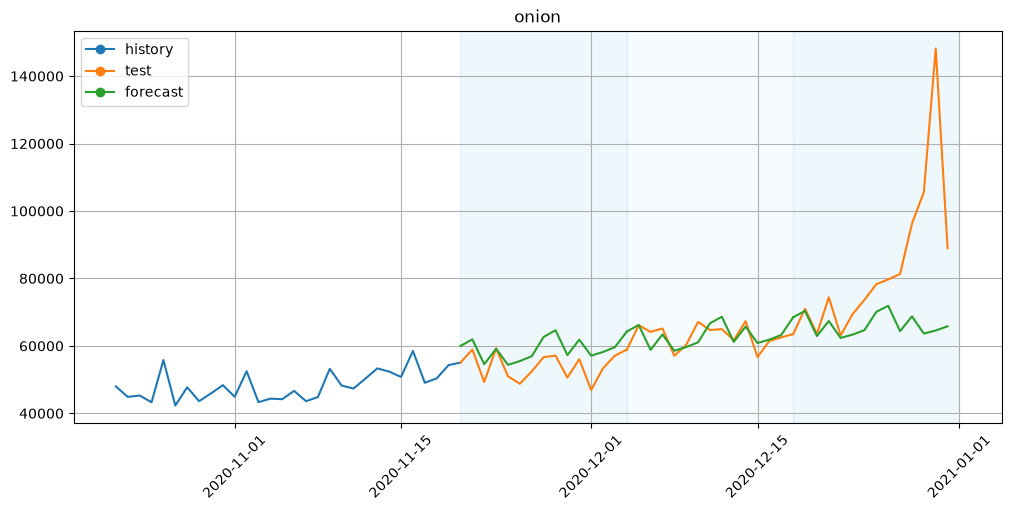

In [20]:
plot_backtest(results["+ праздники + окно 7 дней до"]["forecasts"], onion, history_len=30)

Выигрыш маленький, и на графике видно почему: в последнем фолде модель не ловит
**предновогодний рост** — спрос нарастает всю последнюю неделю декабря и максимален 30–31
числа. Общий флаг «праздник» усредняет Новый год с 23 февраля и 12 июня, а флаг
«скоро праздник» одинаков для 7-го и 1-го дня до события — форму нарастания он не передаёт.

### Признак под конкретное событие

Знание предметной области сильнее общего календаря. Сделаем отдельные индикаторы для
каждого из 10 дней перед Новым годом: модель сама подберёт коэффициент для каждого дня,
то есть выучит форму предпраздничного роста. Это обычный known-future экзогенный признак:
даты известны заранее, передаём их в `TSDataset` через `df_exog`.

In [21]:
dates = pd.date_range("2018-01-01", "2021-01-31", freq="D")
days_to_new_year = (pd.to_datetime((dates.year + 1).astype(str) + "-01-01") - dates).days
pre_new_year = pd.DataFrame(
    {f"new_year_minus_{k}": (days_to_new_year == k).astype(int) for k in range(1, 11)}
).assign(timestamp=dates, segment="onion")

onion_df = onion.to_pandas(flatten=True)[["timestamp", "segment", "target"]]
onion_with_events = common.make_ts(onion_df, exog=pre_new_year)
results["+ праздники + 10 дней до Нового года"] = common.backtest(
    LinearPerSegmentModel(), base + [holidays], onion_with_events, HORIZON
)
common.compare(results)

,WAPE,MAE
база,0.1161,8519.2149
+ праздники,0.1138,8195.6714
+ праздники + окно 7 дней до,0.1131,8177.3845
+ праздники + 10 дней до Нового года,0.0662,4458.7999


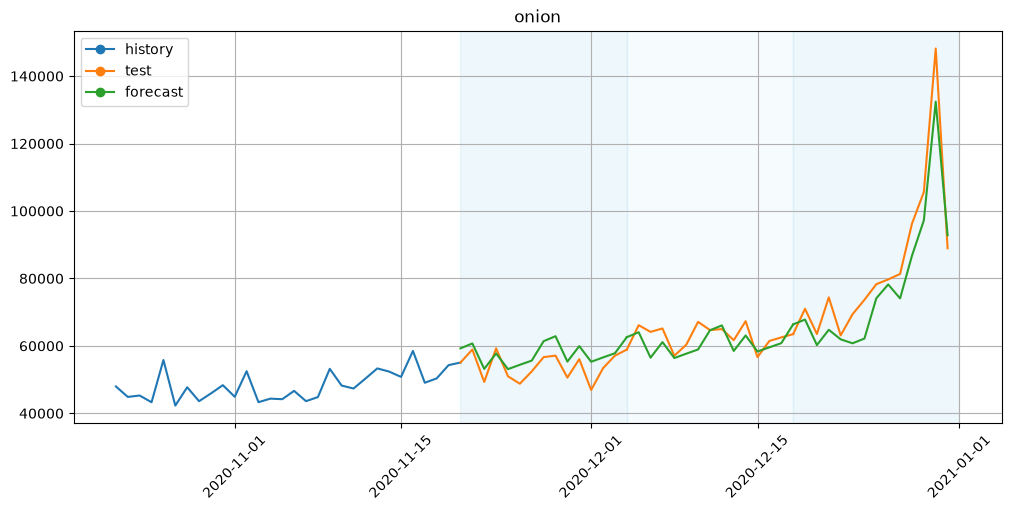

In [22]:
plot_backtest(results["+ праздники + 10 дней до Нового года"]["forecasts"], onion, history_len=30)

Ошибка падает почти вдвое, и почти весь выигрыш — в последнем, декабрьском фолде.

**Выводы.**
- Готовый календарь (`HolidayTransform`) — хорошая отправная точка, но он не знает, какие
  праздники важны **для вашего ряда** и как устроен эффект вокруг них.
- Сильные события стоит кодировать отдельно, иногда — набором индикаторов по дням до/после
  события, чтобы модель выучила форму эффекта.
- Признаки событий — known-future: календарь собственных акций, распродаж, переносов
  выходных (как в `data/events_hw_3.csv`) передаётся через `df_exog` так же, как здесь.

## Итог

| Признаки | WAPE |
|---|---|
| сезонный наивный прогноз | 0.143 |
| тренд + день недели | 0.209 |
| + годовой Фурье | 0.116 |
| + праздники + 10 дней до Нового года | 0.066 |

Все эти признаки — функции даты, они известны на любой горизонт. Следующий шаг (ноутбук 2) —
признаки из **истории ряда**: лаги и окна.